In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = '4'
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'
import h5py
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from utils.models import *
from utils.dataloader import *
from utils.utils_sig import *
from utils.Loss import *


# onebyone

In [17]:
def calculate_batch_mae(preds, targets, fs=30):
    
    mae_sum = 0.0
    valid_count = 0
    
    # GPU 텐서를 CPU 넘파이 배열로 변
    
    # 2. FFT 기반 HR 추출
    pred_hr, _, _ = hr_fft(preds, fs)
    gt_hr, _, _ = hr_fft(targets, fs)
    
    mae = abs(pred_hr - gt_hr)
            
    return mae

def z_norm_per_sample(x):
    # x: (B, T)
    mean = x.mean(dim=-1, keepdim=True)   # (B, 1)
    std  = x.std(dim=-1, keepdim=True)    # (B, 1)
    return (x - mean) / (std + 1e-8)      # per-sample


(122,)
-12
모델 로드 완료
['/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_without_registration_cropped/dataset_wo_registration_cropped_A005_20250611.h5']


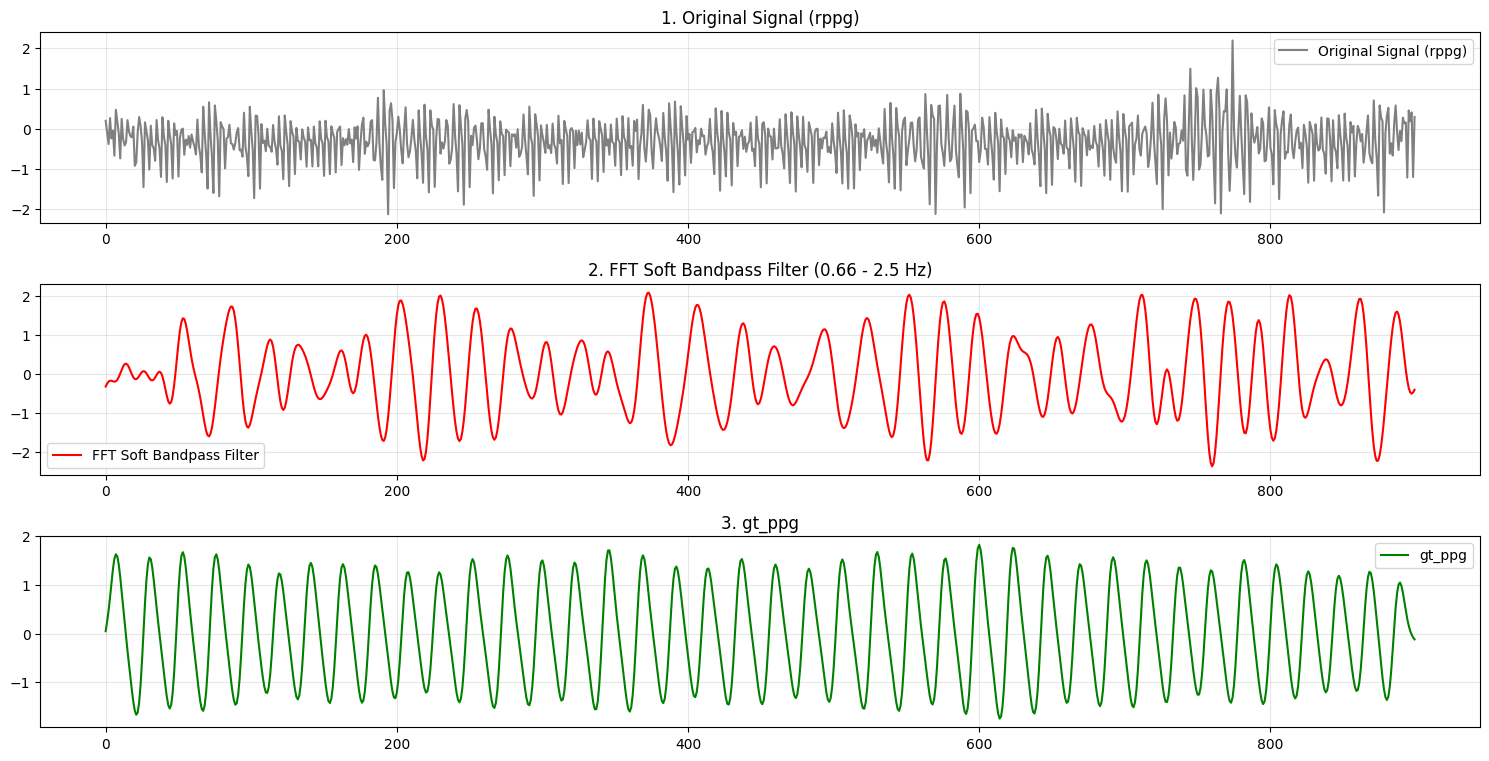

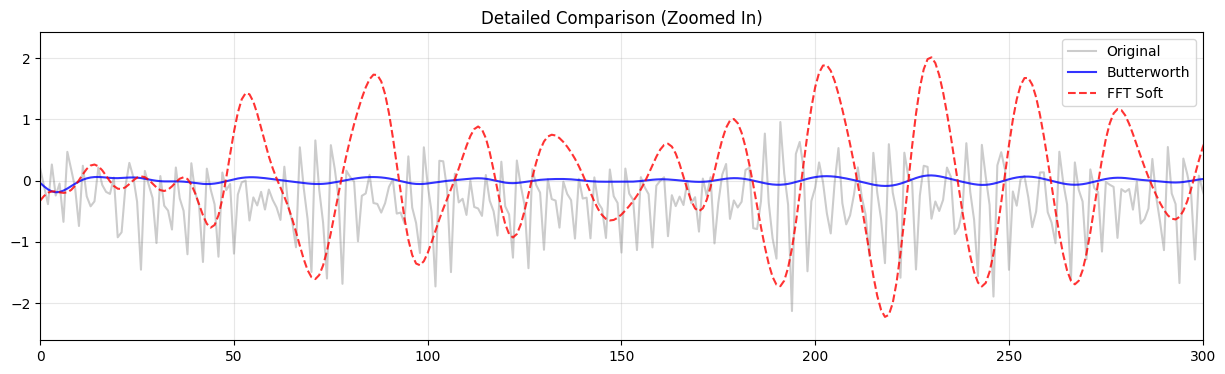

soft fft : 5.2734375 butter : 5.2734375
전체 통째로 계산한 Loss: 0.8936
6조각으로 나누어 평균낸 Loss: 0.9006
각 조각별 Loss: [1.1308, 0.5038, 0.5899, 0.6792, 0.914, 1.5861]


In [18]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from scipy.signal import butter, filtfilt

shifts = np.load('/home/son/orientation-uv-rppg/data/shift_list_save/CNA_data/with_regis_900frmae_bandpassbeforelosscompute_negcorshift/best_val_shifts_41.npy')
print(shifts.shape)
shift_1  = shifts[0]
print(shift_1)

# ===== 설정 및 모델 로드 =====
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pth_path = '/home/son/orientation-uv-rppg/data/parameter_save/300franewithoutregis/klloss+ncorshift/0.0001_epoch:80_MAE: 11.04.pth'
data_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_without_registration_cropped'
pic_save_dir ='/home/son/orientation-uv-rppg/data/pics'

model = PhysNet_padding_Encoder_Decoder_MAX().to(device)
model.load_state_dict(torch.load(pth_path, map_location=device))
model.eval()
print("모델 로드 완료")

# ===== 데이터 로드 및 추론 =====

all_files = [os.path.join(data_dir, u) for u in sorted(os.listdir(data_dir)) if u.endswith('.h5') ]
valid_files = all_files[3:4]
print(valid_files)
valid_dataset = rPPGDataset(valid_files)

input_vid , gt_ppg, _ = valid_dataset[1]
input_vid = input_vid.unsqueeze(0)

# 💡 1. 데이터를 모델과 같은 디바이스(GPU)로 이동
input_vid = input_vid.to(device)

# 💡 2. 기울기 계산 방지 (추론 모드)
with torch.no_grad():
    rppg  = model(input_vid)

# 💡 3. SciPy 필터 및 시각화를 위해 CPU로 내리고 NumPy 1D 배열로 변환
rppg_np = rppg.cpu().numpy().flatten()


# ===== 1. 필터 함수 정의 =====
def butter_bandpass_filter(data, lowcut = 0.66, highcut= 2.5 , fs = 30 , order=4):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    y = filtfilt(b, a, data)
    return y

def bandpass_fft_soft(signal, fs=30, low_hz=0.66, high_hz=2.5, steepness=50.0):
    is_numpy = isinstance(signal, np.ndarray)
    if is_numpy:
        signal = torch.tensor(signal, dtype=torch.float32)
        
    N = signal.shape[-1]
    freqs = torch.fft.rfftfreq(N, d=1.0/fs).to(signal.device)
    fft_signal = torch.fft.rfft(signal)
    mask = torch.sigmoid(steepness * (freqs - low_hz)) * \
           torch.sigmoid(steepness * (high_hz - freqs))
    fft_filtered = fft_signal * mask
    filtered = torch.fft.irfft(fft_filtered, n=N)
    
    if is_numpy:
        return filtered.cpu().numpy()
    return filtered

ncor = Neg_Pearson()

def get_cor_sliced (rppg, ppg, window_num) :
    signal_size = rppg.shape[-1]
    window_size = signal_size // window_num
    cor_list = []
    for i in range(0, window_num) :
        rppg_sliced = rppg[i*window_size : (i+1) * window_size].unsqueeze(0)
        ppg_sliced = ppg[i*window_size : (i+1) * window_size].unsqueeze(0)
        cor_list.append(ncor(rppg_sliced, ppg_sliced).item())
    ncor_mean = sum(cor_list) / window_num
    ncor_whole = ncor(rppg.unsqueeze(0), ppg.unsqueeze(0)).item()

    return cor_list, ncor_mean, ncor_whole

# ===== 3. 필터 적용 =====
# 이제 rppg_np는 numpy 배열이므로 에러 없이 잘 작동합니다.
butter_filtered = butter_bandpass_filter(rppg_np)
fft_soft_filtered = bandpass_fft_soft(rppg_np)
fft_soft_filtered = (fft_soft_filtered - np.mean(fft_soft_filtered)) / np.std(fft_soft_filtered)
# ===== 4. 시각화 (Plot) =====
plt.figure(figsize=(15, 10))

plt.subplot(4, 1, 1)
plt.plot(rppg_np, color='gray', label='Original Signal (rppg)')
plt.title('1. Original Signal (rppg)')
plt.legend()
plt.grid(True, alpha=0.3)

# plt.subplot(4, 1, 2)
# plt.plot(butter_filtered, color='blue', label='Butterworth Filtered')
# plt.title('2. Butterworth Bandpass Filter (0.66 - 2.5 Hz)')
# plt.legend()
# plt.grid(True, alpha=0.3)

plt.subplot(4, 1, 2)
plt.plot(fft_soft_filtered, color='red', label='FFT Soft Bandpass Filter')
plt.title('2. FFT Soft Bandpass Filter (0.66 - 2.5 Hz)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(4, 1, 3)
plt.plot(gt_ppg, color='green', label='gt_ppg')
plt.title('3. gt_ppg')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ===== 5. 겹쳐서 확대 비교해보기 =====
plt.figure(figsize=(15, 4))
# 💡 4. 아래 orig_sig 를 rppg_np로 변경
plt.plot(rppg_np, color='gray', alpha=0.4, label='Original')
plt.plot(butter_filtered, color='blue', alpha=0.8, label='Butterworth')
plt.plot(fft_soft_filtered, color='red', alpha=0.8, linestyle='--', label='FFT Soft')
plt.title('Detailed Comparison (Zoomed In)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xlim(0, 300) 
plt.show()

print(f'soft fft : {calculate_batch_mae(gt_ppg, fft_soft_filtered)} butter : {calculate_batch_mae(gt_ppg, butter_filtered)}')


rppg_tensor = torch.tensor(fft_soft_filtered.copy(), dtype=torch.float32)


cor_list, ncor_mean, ncor_whole = get_cor_sliced(rppg_tensor, gt_ppg, window_num=6)

print(f"전체 통째로 계산한 Loss: {ncor_whole:.4f}")
print(f"6조각으로 나누어 평균낸 Loss: {ncor_mean:.4f}")
print(f"각 조각별 Loss: {[round(c, 4) for c in cor_list]}")

(122,)
6
모델 로드 완료
['/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_without_registration_cropped/dataset_wo_registration_cropped_C002_20250703.h5']


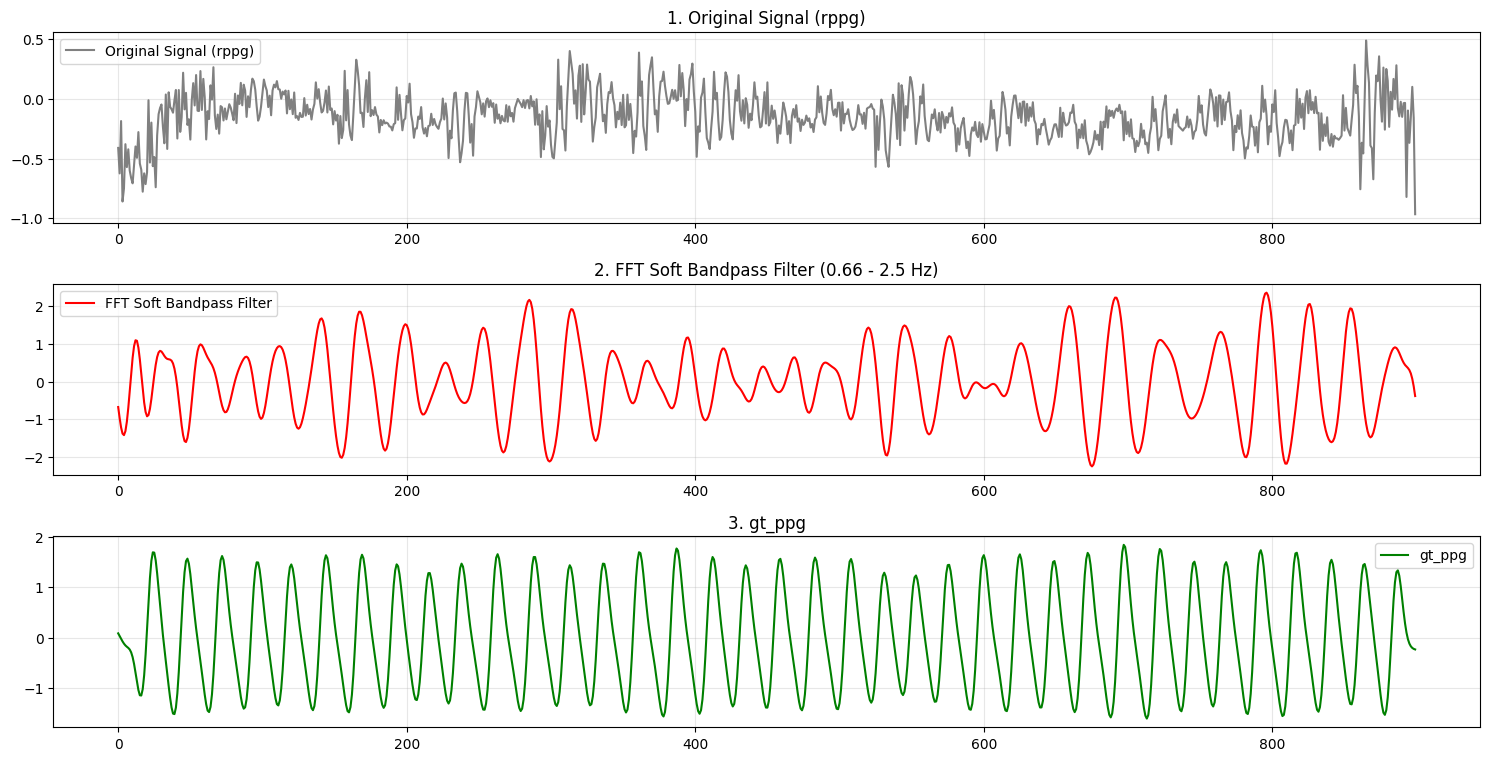

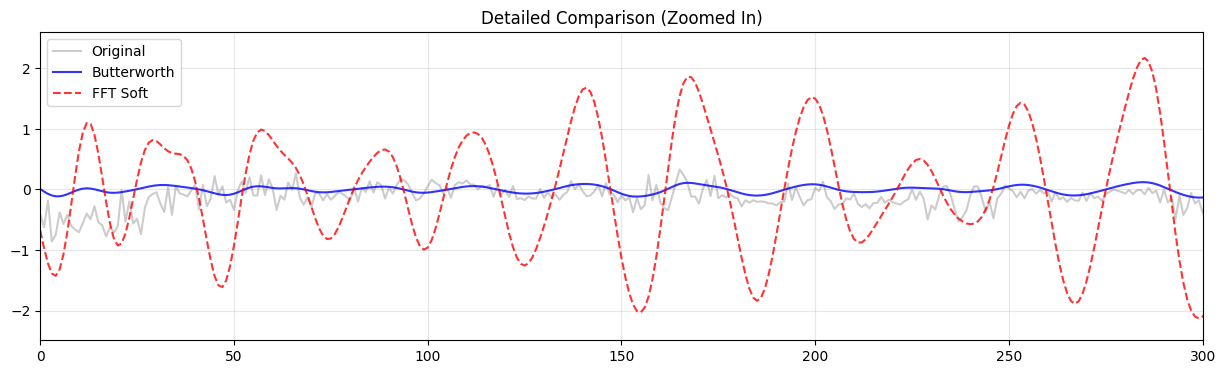

soft fft : 12.744140625 butter : 12.744140625
전체 통째로 계산한 Loss: 1.0339
6조각으로 나누어 평균낸 Loss: 1.0536
각 조각별 Loss: [1.4245, 0.9293, 0.7736, 1.2269, 1.0527, 0.9145]


In [32]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from scipy.signal import butter, filtfilt

shifts = np.load('/home/son/orientation-uv-rppg/data/shift_list_save/CNA_data/with_regis_900frmae_bandpassbeforelosscompute_negcorshift/best_val_shifts_41.npy')
print(shifts.shape)
shift_1  = shifts[2]
print(shift_1)

# ===== 설정 및 모델 로드 =====
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pth_path = '/home/son/orientation-uv-rppg/data/parameter_save/physformer/300franewithoutregis_13out_and_znorm/ncorshift+kldiv/0.0001_epoch:61_MAE: 13.14.pth'
data_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_without_registration_cropped'
pic_save_dir ='/home/son/orientation-uv-rppg/data/pics'

base_model = ViT_ST_ST_Compact3_TDC_gra_sharp(
    image_size=(300, 64, 64), 
    patches=(4, 4, 4), # 중요: 공간 해상도를 4x4로 맞추기 위한 셋업
    in_channels=1, 
    theta=0.2 # CDC_T 활성화
)

class PhysFormerWrapper(nn.Module):
    def __init__(self, base_model, gra_sharp=2.0):
        super().__init__()
        self.model = base_model
        self.gra_sharp = gra_sharp # 논문 디폴트 2.0

    def forward(self, x):
        # 1. 원본 모델에 필수 인자인 gra_sharp를 함께 넘겨줌
        # 2. 반환되는 (rPPG, Score1, Score2, Score3) 중 첫 번째 rPPG만 가져옴
        rPPG, _, _, _ = self.model(x, self.gra_sharp)
        return rPPG

model = PhysFormerWrapper(base_model).to(device)
state_dict = torch.load(pth_path, map_location='cpu') # 일단 CPU로 읽어옴
model.load_state_dict(state_dict) 
model.to(device) # 그 다음 GPU로 이동
del state_dict
model.eval()
print("모델 로드 완료")

# ===== 데이터 로드 및 추론 =====

all_files = [os.path.join(data_dir, u) for u in sorted(os.listdir(data_dir)) if u.endswith('.h5') ]
valid_files = all_files[14:15]
print(valid_files)
valid_dataset = rPPGDataset(valid_files)

input_vid , gt_ppg, _ = valid_dataset[1]
input_vid = input_vid.unsqueeze(0)

# 💡 1. 데이터를 모델과 같은 디바이스(GPU)로 이동
input_vid = input_vid.to(device)

# 💡 2. 기울기 계산 방지 (추론 모드)
with torch.no_grad():
    rppg = model(input_vid)

# 💡 3. SciPy 필터 및 시각화를 위해 CPU로 내리고 NumPy 1D 배열로 변환
rppg_np = rppg.cpu().numpy().flatten()


# ===== 1. 필터 함수 정의 =====
def butter_bandpass_filter(data, lowcut = 0.66, highcut= 2.5 , fs = 30 , order=4):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    y = filtfilt(b, a, data)
    return y

def bandpass_fft_soft(signal, fs=30, low_hz=0.66, high_hz=2.5, steepness=50.0):
    is_numpy = isinstance(signal, np.ndarray)
    if is_numpy:
        signal = torch.tensor(signal, dtype=torch.float32)
        
    N = signal.shape[-1]
    freqs = torch.fft.rfftfreq(N, d=1.0/fs).to(signal.device)
    fft_signal = torch.fft.rfft(signal)
    mask = torch.sigmoid(steepness * (freqs - low_hz)) * \
           torch.sigmoid(steepness * (high_hz - freqs))
    fft_filtered = fft_signal * mask
    filtered = torch.fft.irfft(fft_filtered, n=N)
    
    if is_numpy:
        return filtered.cpu().numpy()
    return filtered

ncor = Neg_Pearson()

def get_cor_sliced (rppg, ppg, window_num) :
    signal_size = rppg.shape[-1]
    window_size = signal_size // window_num
    cor_list = []
    for i in range(0, window_num) :
        rppg_sliced = rppg[i*window_size : (i+1) * window_size].unsqueeze(0)
        ppg_sliced = ppg[i*window_size : (i+1) * window_size].unsqueeze(0)
        cor_list.append(ncor(rppg_sliced, ppg_sliced).item())
    ncor_mean = sum(cor_list) / window_num
    ncor_whole = ncor(rppg.unsqueeze(0), ppg.unsqueeze(0)).item()

    return cor_list, ncor_mean, ncor_whole

# ===== 3. 필터 적용 =====
# 이제 rppg_np는 numpy 배열이므로 에러 없이 잘 작동합니다.
butter_filtered = butter_bandpass_filter(rppg_np)
fft_soft_filtered = bandpass_fft_soft(rppg_np)
fft_soft_filtered = (fft_soft_filtered - np.mean(fft_soft_filtered)) / np.std(fft_soft_filtered)
# ===== 4. 시각화 (Plot) =====
plt.figure(figsize=(15, 10))

plt.subplot(4, 1, 1)
plt.plot(rppg_np, color='gray', label='Original Signal (rppg)')
plt.title('1. Original Signal (rppg)')
plt.legend()
plt.grid(True, alpha=0.3)

# plt.subplot(4, 1, 2)
# plt.plot(butter_filtered, color='blue', label='Butterworth Filtered')
# plt.title('2. Butterworth Bandpass Filter (0.66 - 2.5 Hz)')
# plt.legend()
# plt.grid(True, alpha=0.3)

plt.subplot(4, 1, 2)
plt.plot(fft_soft_filtered, color='red', label='FFT Soft Bandpass Filter')
plt.title('2. FFT Soft Bandpass Filter (0.66 - 2.5 Hz)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(4, 1, 3)
plt.plot(gt_ppg, color='green', label='gt_ppg')
plt.title('3. gt_ppg')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ===== 5. 겹쳐서 확대 비교해보기 =====
plt.figure(figsize=(15, 4))
# 💡 4. 아래 orig_sig 를 rppg_np로 변경
plt.plot(rppg_np, color='gray', alpha=0.4, label='Original')
plt.plot(butter_filtered, color='blue', alpha=0.8, label='Butterworth')
plt.plot(fft_soft_filtered, color='red', alpha=0.8, linestyle='--', label='FFT Soft')
plt.title('Detailed Comparison (Zoomed In)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xlim(0, 300) 
plt.show()

print(f'soft fft : {calculate_batch_mae(gt_ppg, fft_soft_filtered)} butter : {calculate_batch_mae(gt_ppg, butter_filtered)}')


rppg_tensor = torch.tensor(fft_soft_filtered.copy(), dtype=torch.float32)


cor_list, ncor_mean, ncor_whole = get_cor_sliced(rppg_tensor, gt_ppg, window_num=6)

print(f"전체 통째로 계산한 Loss: {ncor_whole:.4f}")
print(f"6조각으로 나누어 평균낸 Loss: {ncor_mean:.4f}")
print(f"각 조각별 Loss: {[round(c, 4) for c in cor_list]}")

# all

모델 로드 완료
추론 완료: preds (100, 900), targets (100, 900)


AttributeError: 'numpy.ndarray' object has no attribute 'detach'

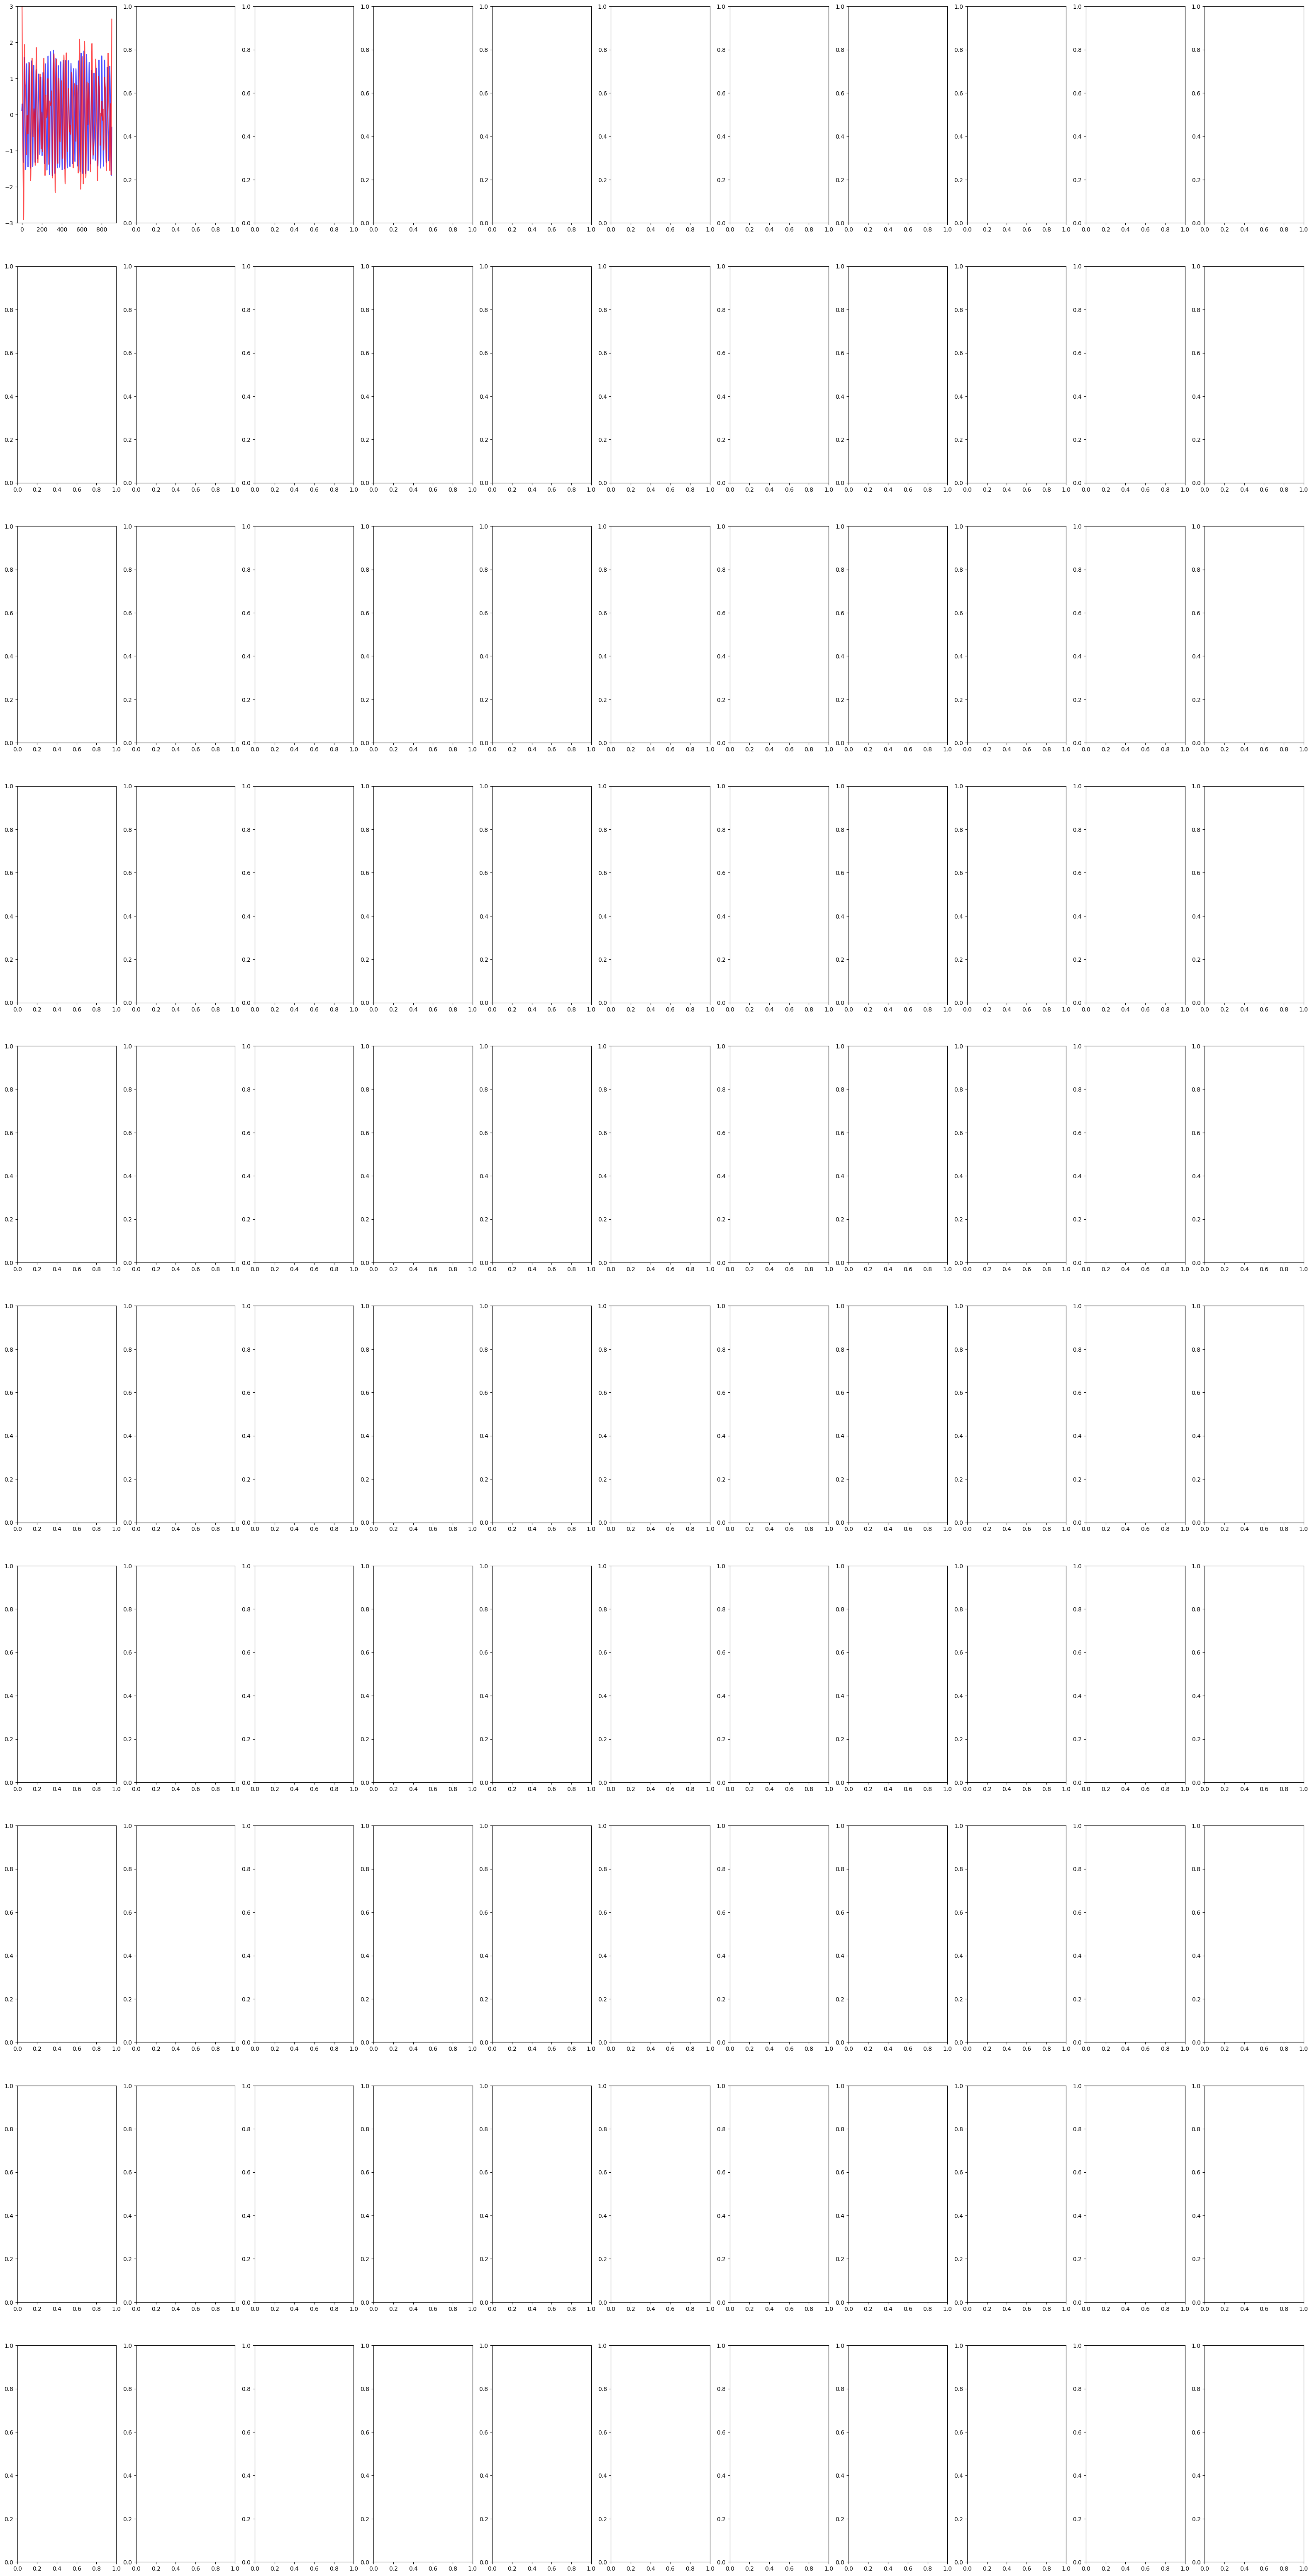

In [16]:
# ===== 설정 =====
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pth_path = '/home/son/orientation-uv-rppg/data/parameter_save/300franewithoutregis/klloss+ncorshift/0.0001_epoch:80_MAE: 11.04.pth'
data_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_without_registration_cropped'
pic_save_dir ='/home/son/orientation-uv-rppg/data/pics'
# ===== 모델 로드 =====


model = PhysNet_padding_Encoder_Decoder_MAX().to(device)
model.load_state_dict(torch.load(pth_path, map_location=device))
model.eval()
print("모델 로드 완료")

# ===== 데이터 로드 =====
all_files = sorted([os.path.join(data_dir, f) for f in os.listdir(data_dir) if f.endswith('.h5')])
valid_files = all_files[1:2]
valid_dataset = rPPGDataset(valid_files)
valid_loader  = DataLoader(valid_dataset, batch_size=2, shuffle=False, num_workers=4)

# ===== 추론 =====
all_preds   = []
all_targets = []
all_preds_with_filter = []
all_cor_list = []
fil_cor_list = []

def bandpass_fft_soft(signal, fs=30, low_hz=0.66, high_hz=3.0, steepness=50.0):
    is_numpy = isinstance(signal, np.ndarray)
    if is_numpy:
        signal = torch.tensor(signal, dtype=torch.float32)
        
    N = signal.shape[-1]
    freqs = torch.fft.rfftfreq(N, d=1.0/fs).to(signal.device)
    fft_signal = torch.fft.rfft(signal)
    mask = torch.sigmoid(steepness * (freqs - low_hz)) * \
           torch.sigmoid(steepness * (high_hz - freqs))
    fft_filtered = fft_signal * mask
    filtered = torch.fft.irfft(fft_filtered, n=N)
    
    if is_numpy:
        return filtered.cpu().numpy()
    return filtered


with torch.no_grad():
    for inputs, targets, hr in valid_loader:
        inputs  = inputs.to(device)
        outputs = model(inputs)

        if outputs.shape[-1] != targets.shape[-1] :
            outputs = outputs[:,:-1]

        all_preds.append(outputs.cpu().numpy())
        all_targets.append(targets.numpy())

all_preds   = np.concatenate(all_preds,   axis=0)  # (N, 300)
all_targets = np.concatenate(all_targets, axis=0)  # (N, 300)

all_preds_with_filter = bandpass_fft_soft(all_preds, fs=30, low_hz=0.66, high_hz=2.5)

print(f"추론 완료: preds {all_preds.shape}, targets {all_targets.shape}")

Los = Neg_Pearson()

# ===== Plot =====
n_plot = len(all_preds_with_filter)  # 몇 개 샘플 볼지
fig, axes = plt.subplots(10, n_plot//10 + 1, figsize=(40, 80))
axes = axes.flatten()
mae_list = []
for i in range(n_plot):
    # 코드가 길어지는 것을 방지하기 위해 변수에 할당
    gt_sig = all_targets[i]
    pred_sig_filt =  all_preds_with_filter[i] 
    pred_sig_orig = all_preds[i]
    # 신호 그리기
    axes[i].plot(gt_sig, label='GT', color='blue', alpha=0.7)
    axes[i].plot( (pred_sig_filt - np.mean(pred_sig_filt)) / (np.std(pred_sig_filt) +1e-8) , label='Predicted with filter', color='red', alpha=0.7 )
    #axes[i].plot(pred_sig_orig,   label='Predicted', color='green',   alpha=0.7)
    axes[i].set_ylim(-3,3)
    maes = calculate_batch_mae(gt_sig,(pred_sig_filt - np.mean(pred_sig_filt) / (np.std(pred_sig_filt) +1e-8) ))
    
    # --- 💡 평균값 계산 및 수평선 그리기 추가 💡 ---
    gt_mean = np.mean(gt_sig)
    pred_mean = np.mean(pred_sig_filt)
    
    axes[i].axhline(y=gt_mean, color='darkblue', linestyle='--', alpha=0.8, 
                    label=f'GT Mean ({gt_mean:.2f})')
    axes[i].axhline(y=pred_mean, color='darkred', linestyle='--', alpha=0.8, 
                    label=f'Pred Mean ({pred_mean:.2f})')
    # ---------------------------------------------


    cor_all_win = Los(torch.tensor(pred_sig_orig.copy(), dtype=torch.float32).unsqueeze(0), 
                    torch.tensor(gt_sig.copy(), dtype=torch.float32).unsqueeze(0))
    cor_after_filter  = Los(torch.tensor(pred_sig_filt.copy(), dtype=torch.float32).unsqueeze(0), 
                    torch.tensor(gt_sig.copy(),   dtype=torch.float32).unsqueeze(0))
    all_cor_list.append(cor_all_win)
    fil_cor_list.append(cor_after_filter)
    axes[i].set_title(f'|mae : {maes}|')
    mae_list.append(maes)

    # 범례가 많아지므로 폰트 크기를 살짝 줄이거나 위치를 조정하는 것도 좋습니다.
    axes[i].legend(loc='upper right', fontsize='small') 
    axes[i].set_xlabel('Frame')


plt.tight_layout()
plt.savefig(os.path.join(pic_save_dir, '0521_900frame_for_hrv'), dpi= 100)
plt.show()
print(f'mae_mean : {np.mean(mae_list)} mae_std : {np.std(mae_list)}')


In [11]:
# ===== 설정 =====
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pth_path = '/home/son/orientation-uv-rppg/data/parameter_save/physformer/300franewithoutregis_13out_and_znorm/bandpassbeforelosscompute_ncorshift/0.0001_epoch:94_MAE: 11.11.pth'
data_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_without_registration_cropped_len300'
pic_save_dir ='/home/son/orientation-uv-rppg/data/pics'
# ===== 모델 로드 =====
base_model = ViT_ST_ST_Compact3_TDC_gra_sharp(
    image_size=(300, 64, 64), 
    patches=(4, 4, 4), # 중요: 공간 해상도를 4x4로 맞추기 위한 셋업
    in_channels=1, 
    theta=0.2 # CDC_T 활성화
)

class PhysFormerWrapper(nn.Module):
    def __init__(self, base_model, gra_sharp=2.0):
        super().__init__()
        self.model = base_model
        self.gra_sharp = gra_sharp # 논문 디폴트 2.0

    def forward(self, x):
        # 1. 원본 모델에 필수 인자인 gra_sharp를 함께 넘겨줌
        # 2. 반환되는 (rPPG, Score1, Score2, Score3) 중 첫 번째 rPPG만 가져옴
        rPPG, _, _, _ = self.model(x, self.gra_sharp)
        return rPPG

model = PhysFormerWrapper(base_model).to(device)
state_dict = torch.load(pth_path, map_location='cpu') # 일단 CPU로 읽어옴
model.load_state_dict(state_dict) 
model.to(device) # 그 다음 GPU로 이동
del state_dict
model.eval()
print("모델 로드 완료")

# ===== 데이터 로드 =====
all_files = sorted([os.path.join(data_dir, f) for f in os.listdir(data_dir) if f.endswith('.h5')])
valid_files = all_files[13:14]
valid_dataset = rPPGDataset(valid_files)
valid_loader  = DataLoader(valid_dataset, batch_size=2, shuffle=False, num_workers=4)

# ===== 추론 =====
all_preds   = []
all_targets = []
all_preds_with_filter = []
all_cor_list = []
fil_cor_list = []

def bandpass_fft_soft(signal, fs=30, low_hz=0.66, high_hz=2.5, steepness=50.0):
    is_numpy = isinstance(signal, np.ndarray)
    if is_numpy:
        signal = torch.tensor(signal, dtype=torch.float32)
        
    N = signal.shape[-1]
    freqs = torch.fft.rfftfreq(N, d=1.0/fs).to(signal.device)
    fft_signal = torch.fft.rfft(signal)
    mask = torch.sigmoid(steepness * (freqs - low_hz)) * \
           torch.sigmoid(steepness * (high_hz - freqs))
    fft_filtered = fft_signal * mask
    filtered = torch.fft.irfft(fft_filtered, n=N)
    
    if is_numpy:
        return filtered.cpu().numpy()
    return filtered


with torch.no_grad():
    for inputs, targets, hr in valid_loader:
        inputs  = inputs.to(device)
        outputs = model(inputs)

        all_preds.append(outputs.cpu().numpy())
        all_targets.append(targets.numpy())

all_preds   = np.concatenate(all_preds,   axis=0)  # (N, 300)
all_targets = np.concatenate(all_targets, axis=0)  # (N, 300)

all_preds_with_filter = bandpass_fft_soft(all_preds, fs=30, low_hz=0.66, high_hz=2.5)

print(f"추론 완료: preds {all_preds.shape}, targets {all_targets.shape}")

Los = Neg_Pearson()

# ===== Plot =====
n_plot = len(all_preds_with_filter)  # 몇 개 샘플 볼지
fig, axes = plt.subplots(4, 5, figsize=(20, 30))
axes = axes.flatten()
mae_list = []
for i in range(20):
    # 코드가 길어지는 것을 방지하기 위해 변수에 할당
    gt_sig = all_targets[i]
    pred_sig_filt =  all_preds_with_filter[i] 
    pred_sig_orig = all_preds[i]
    # 신호 그리기
    axes[i].plot(gt_sig, label='GT', color='blue', alpha=0.7)
    axes[i].plot( (pred_sig_filt - np.mean(pred_sig_filt)) / (np.std(pred_sig_filt) +1e-8) , label='Predicted with filter', color='red', alpha=0.7 )
    #axes[i].plot(pred_sig_orig,   label='Predicted', color='green',   alpha=0.7)
    axes[i].set_ylim(-3,3)
    maes = calculate_batch_mae(gt_sig,(pred_sig_filt - np.mean(pred_sig_filt) / (np.std(pred_sig_filt) +1e-8) ))
    
    # --- 💡 평균값 계산 및 수평선 그리기 추가 💡 ---
    gt_mean = np.mean(gt_sig)
    pred_mean = np.mean(pred_sig_filt)
    
    axes[i].axhline(y=gt_mean, color='darkblue', linestyle='--', alpha=0.8, 
                    label=f'GT Mean ({gt_mean:.2f})')
    axes[i].axhline(y=pred_mean, color='darkred', linestyle='--', alpha=0.8, 
                    label=f'Pred Mean ({pred_mean:.2f})')
    # ---------------------------------------------


    cor_all_win = Los(torch.tensor(pred_sig_orig.copy(), dtype=torch.float32).unsqueeze(0), 
                    torch.tensor(gt_sig.copy(), dtype=torch.float32).unsqueeze(0))
    cor_after_filter  = Los(torch.tensor(pred_sig_filt.copy(), dtype=torch.float32).unsqueeze(0), 
                    torch.tensor(gt_sig.copy(),   dtype=torch.float32).unsqueeze(0))
    all_cor_list.append(cor_all_win)
    fil_cor_list.append(cor_after_filter)
    axes[i].set_title(f'|mae : {maes}|')
    mae_list.append(maes)

    # 범례가 많아지므로 폰트 크기를 살짝 줄이거나 위치를 조정하는 것도 좋습니다.
    axes[i].legend(loc='upper right', fontsize='small') 
    axes[i].set_xlabel('Frame')


plt.tight_layout()
plt.savefig(os.path.join(pic_save_dir, 'slice_ncor_nonormalize_timedomain_test15_lowestmaeepoch_sclaeup'), dpi= 100)
plt.show()
print(f'mae_mean : {np.mean(mae_list)} mae_std : {np.std(mae_list)}')


KeyboardInterrupt: 

# hrv

모델 로드 완료
['/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/driving_cropped_dl_data/subject3_garage_large_motion_975_dldata.h5']
Computing HRV for 4 conditions...
⚠️ HRV failed: cannot convert float NaN to integer

Feature         GT(Butter)   GT(FFT)      rPPG(Butter)   rPPG(FFT)   
--------------------------------------------------------------------------------
HR (BPM)        83.72        84.05        N/A            73.33       
RMSSD (ms)      100.00       102.49       N/A            934.17      
SDNN (ms)       89.33        89.28        N/A            681.23      
pNN50 (%)       58.33        58.33        N/A            54.55       
LF              nan          nan          N/A            nan         
HF              nan          nan          N/A            nan         
LF/HF           nan          nan          N/A            nan         
# peaks         13.00        13.00        N/A            12.00       
---------------------------------------------------

/home/son/orientation-uv-rppg/venv/lib/python3.10/site-packages/neurokit2/signal/signal_period.py:84: NeuroKitWarning: Too few peaks detected to compute the rate. Returning empty vector.
  warn(
/home/son/orientation-uv-rppg/venv/lib/python3.10/site-packages/neurokit2/complexity/entropy_multiscale.py:349: RuntimeWarning: invalid value encountered in scalar divide
  mse = np.trapz(mse) / len(mse)
/home/son/orientation-uv-rppg/venv/lib/python3.10/site-packages/neurokit2/complexity/optim_complexity_k.py:134: RuntimeWarning: divide by zero encountered in divide
  normalization = (n - 1) / (np.floor((n - k_subrange) / k).astype(int) * k)
/home/son/orientation-uv-rppg/venv/lib/python3.10/site-packages/neurokit2/complexity/optim_complexity_k.py:135: RuntimeWarning: invalid value encountered in multiply
  sets = (np.nansum(np.abs(np.diff(sig_values)), axis=1) * normalization) / k
/home/son/orientation-uv-rppg/venv/lib/python3.10/site-packages/neurokit2/hrv/hrv_nonlinear.py:536: NeuroKitWarning


💾 Saved: /home/son/orientation-uv-rppg/data/pics/hrv_filter_comparison.png


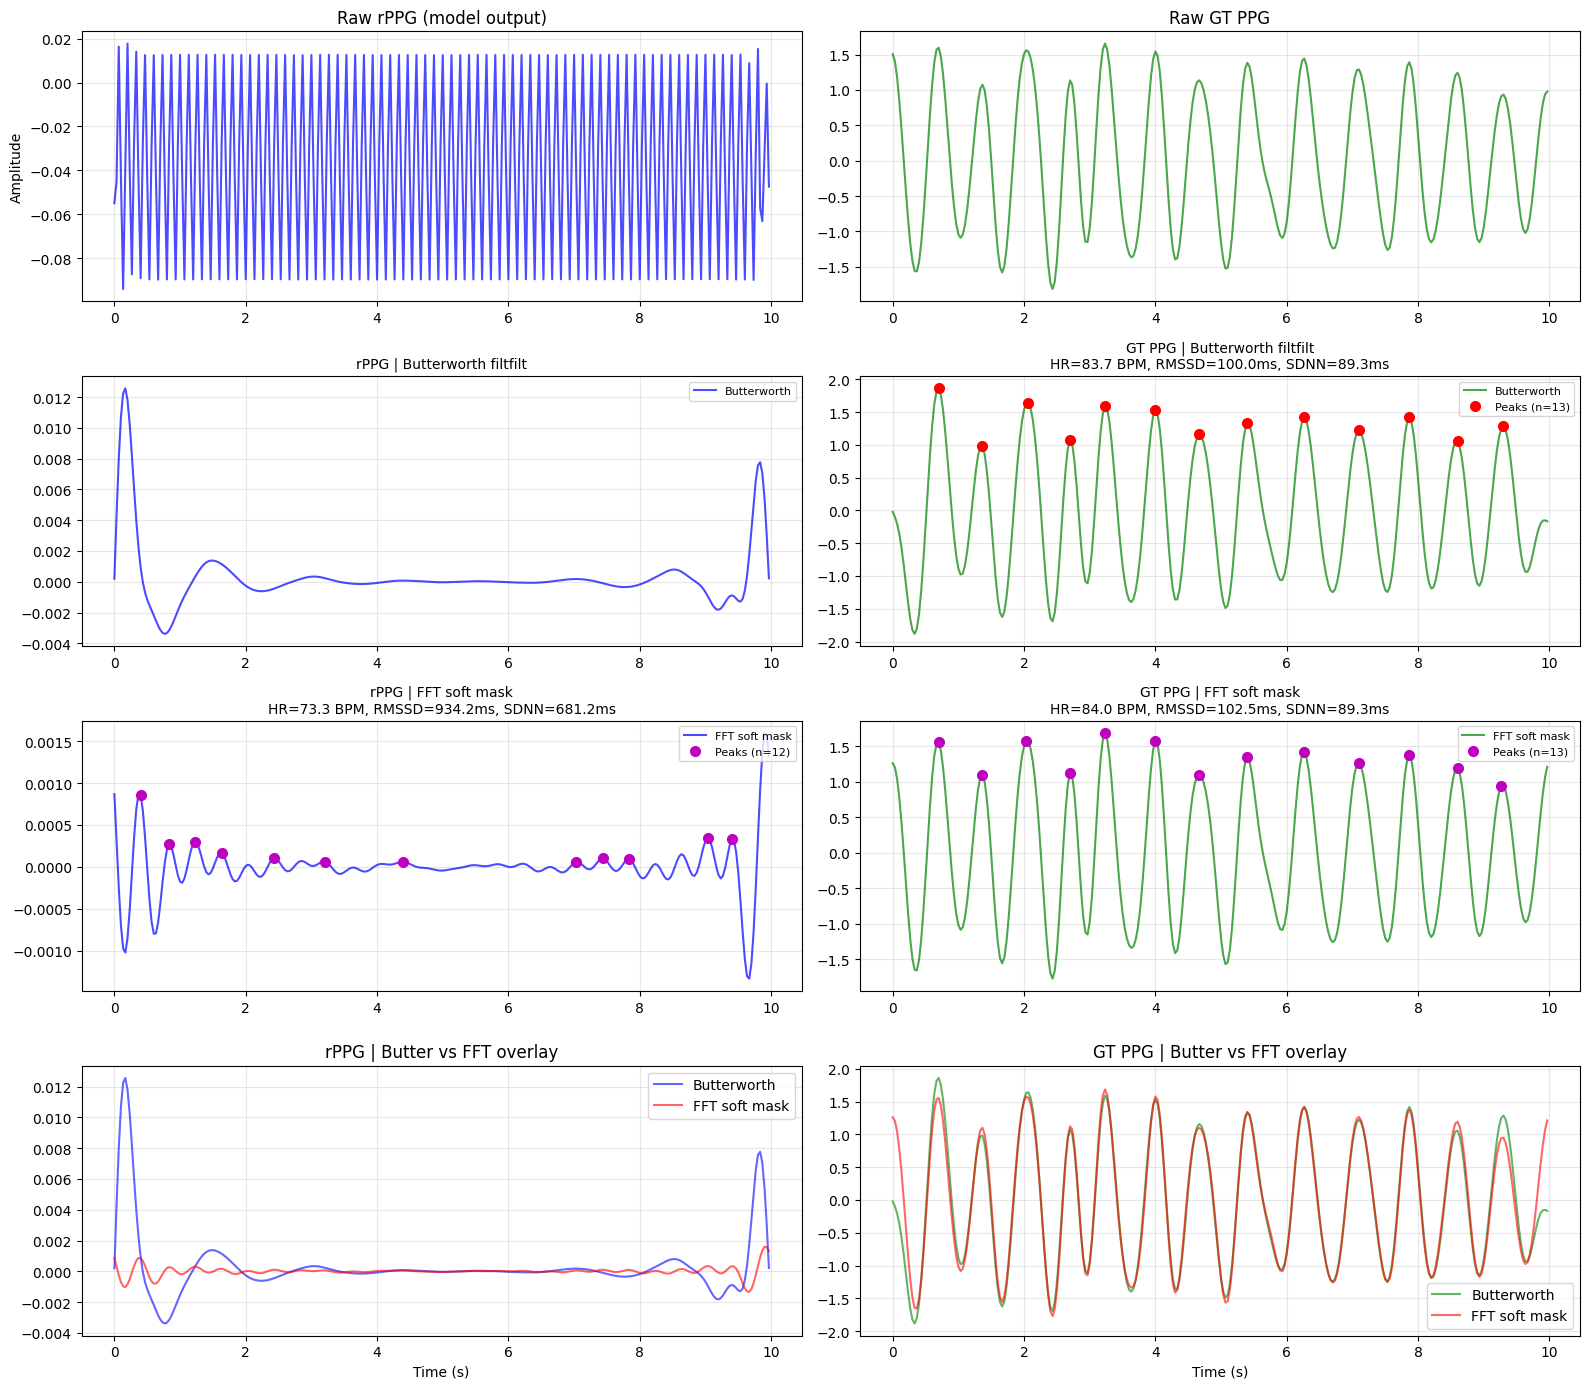

In [21]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
import neurokit2 as nk
from scipy.signal import butter, filtfilt


# ===== 설정 및 모델 로드 =====
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pth_path = '/home/son/orientation-uv-rppg/data/parameter_save/nirpdriving/physnet/LOSO_driving_cropped_ncorshift+kldiv/fold_8/best_model.pth'
data_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/driving_cropped_dl_data'
pic_save_dir ='/home/son/orientation-uv-rppg/data/pics'

model = PhysNet_padding_Encoder_Decoder_MAX().to(device)
model.load_state_dict(torch.load(pth_path, map_location=device))
model.eval()
print("모델 로드 완료")

# ===== 데이터 로드 및 추론 =====

all_files = [os.path.join(data_dir, u) for u in sorted(os.listdir(data_dir)) if u.endswith('.h5') ]
valid_files = all_files[8:9]
print(valid_files)
valid_dataset = rPPGDataset(valid_files)

input_vid , gt_ppg, _ = valid_dataset[5]
input_vid = input_vid.unsqueeze(0)

# 💡 1. 데이터를 모델과 같은 디바이스(GPU)로 이동
input_vid = input_vid.to(device)

# 💡 2. 기울기 계산 방지 (추론 모드)
with torch.no_grad():
    rppg  = model(input_vid)

# 💡 3. SciPy 필터 및 시각화를 위해 CPU로 내리고 NumPy 1D 배열로 변환
rppg_np = rppg.cpu().numpy().flatten()
# ─────────────────────────────────────────────────────────────
# 1. 두 가지 bandpass
# ─────────────────────────────────────────────────────────────
def butter_bandpass_filter(data, lowcut=0.66, highcut=2.5, fs=30, order=4):
    """Zero-phase Butterworth bandpass (HRV 평가 표준)"""
    nyq = 0.5 * fs
    b, a = butter(order, [lowcut/nyq, highcut/nyq], btype='band')
    return filtfilt(b, a, data)


def bandpass_fft_soft(signal, fs=30, low_hz=0.66, high_hz=2.5, steepness=50.0):
    """FFT soft mask bandpass (학습용, sigmoid mask)"""
    is_numpy = isinstance(signal, np.ndarray)
    if is_numpy:
        signal = torch.tensor(signal, dtype=torch.float32)
    N = signal.shape[-1]
    freqs = torch.fft.rfftfreq(N, d=1.0/fs).to(signal.device)
    fft_signal = torch.fft.rfft(signal)
    mask = torch.sigmoid(steepness * (freqs - low_hz)) * \
           torch.sigmoid(steepness * (high_hz - freqs))
    fft_filtered = fft_signal * mask
    filtered = torch.fft.irfft(fft_filtered, n=N)
    if is_numpy:
        return filtered.cpu().numpy()
    return filtered


# ─────────────────────────────────────────────────────────────
# 2. HRV 계산
# ─────────────────────────────────────────────────────────────
def compute_hrv_from_rppg(rppg_signal, fs=30):
    """Returns hrv_dict, peaks. None on failure."""
    try:
        signals, info = nk.ppg_process(rppg_signal, sampling_rate=fs)
        peaks = info['PPG_Peaks']
        
        if len(peaks) < 5:
            return None, peaks
        
        hrv = nk.hrv(peaks, sampling_rate=fs, show=False)
        
        result = {
            'mean_hr_bpm': 60000 / hrv['HRV_MeanNN'].values[0],
            'rmssd_ms':    hrv['HRV_RMSSD'].values[0],
            'sdnn_ms':     hrv['HRV_SDNN'].values[0],
            'pnn50_pct':   hrv['HRV_pNN50'].values[0],
            'lf_power':    hrv['HRV_LF'].values[0],
            'hf_power':    hrv['HRV_HF'].values[0],
            'lf_hf_ratio': hrv['HRV_LFHF'].values[0],
            'num_peaks':   len(peaks),
        }
        return result, peaks
    except Exception as e:
        print(f"⚠️ HRV failed: {e}")
        return None, []


# ─────────────────────────────────────────────────────────────
# 3. 시각화 — 4-panel 비교
# ─────────────────────────────────────────────────────────────
def visualize_filter_comparison(
    rppg_raw, gt_raw,
    rppg_butter, rppg_fft,
    gt_butter, gt_fft,
    rppg_butter_peaks, rppg_fft_peaks,
    gt_butter_peaks, gt_fft_peaks,
    rppg_butter_hrv, rppg_fft_hrv,
    gt_butter_hrv, gt_fft_hrv,
    fs=30, save_path=None
):
    fig, axes = plt.subplots(4, 2, figsize=(16, 14))
    t = np.arange(len(rppg_raw)) / fs
    
    # ── Row 0: Raw signals ────────────────────────────────────
    axes[0, 0].plot(t, rppg_raw, 'b-', alpha=0.7)
    axes[0, 0].set_title('Raw rPPG (model output)')
    axes[0, 0].set_ylabel('Amplitude')
    axes[0, 0].grid(True, alpha=0.3)
    
    axes[0, 1].plot(t, gt_raw, 'g-', alpha=0.7)
    axes[0, 1].set_title('Raw GT PPG')
    axes[0, 1].grid(True, alpha=0.3)
    
    # ── Row 1: Butterworth filtered + peaks ────────────────────
    axes[1, 0].plot(t, rppg_butter, 'b-', alpha=0.7, label='Butterworth')
    if len(rppg_butter_peaks) > 0:
        axes[1, 0].plot(rppg_butter_peaks/fs, rppg_butter[rppg_butter_peaks], 
                        'ro', markersize=7, label=f'Peaks (n={len(rppg_butter_peaks)})')
    title = 'rPPG | Butterworth filtfilt'
    if rppg_butter_hrv:
        title += f'\nHR={rppg_butter_hrv["mean_hr_bpm"]:.1f} BPM, RMSSD={rppg_butter_hrv["rmssd_ms"]:.1f}ms, SDNN={rppg_butter_hrv["sdnn_ms"]:.1f}ms'
    axes[1, 0].set_title(title, fontsize=10)
    axes[1, 0].legend(loc='upper right', fontsize=8)
    axes[1, 0].grid(True, alpha=0.3)
    
    axes[1, 1].plot(t, gt_butter, 'g-', alpha=0.7, label='Butterworth')
    if len(gt_butter_peaks) > 0:
        axes[1, 1].plot(gt_butter_peaks/fs, gt_butter[gt_butter_peaks], 
                        'ro', markersize=7, label=f'Peaks (n={len(gt_butter_peaks)})')
    title = 'GT PPG | Butterworth filtfilt'
    if gt_butter_hrv:
        title += f'\nHR={gt_butter_hrv["mean_hr_bpm"]:.1f} BPM, RMSSD={gt_butter_hrv["rmssd_ms"]:.1f}ms, SDNN={gt_butter_hrv["sdnn_ms"]:.1f}ms'
    axes[1, 1].set_title(title, fontsize=10)
    axes[1, 1].legend(loc='upper right', fontsize=8)
    axes[1, 1].grid(True, alpha=0.3)
    
    # ── Row 2: FFT soft mask filtered + peaks ──────────────────
    axes[2, 0].plot(t, rppg_fft, 'b-', alpha=0.7, label='FFT soft mask')
    if len(rppg_fft_peaks) > 0:
        axes[2, 0].plot(rppg_fft_peaks/fs, rppg_fft[rppg_fft_peaks], 
                        'mo', markersize=7, label=f'Peaks (n={len(rppg_fft_peaks)})')
    title = 'rPPG | FFT soft mask'
    if rppg_fft_hrv:
        title += f'\nHR={rppg_fft_hrv["mean_hr_bpm"]:.1f} BPM, RMSSD={rppg_fft_hrv["rmssd_ms"]:.1f}ms, SDNN={rppg_fft_hrv["sdnn_ms"]:.1f}ms'
    axes[2, 0].set_title(title, fontsize=10)
    axes[2, 0].legend(loc='upper right', fontsize=8)
    axes[2, 0].grid(True, alpha=0.3)
    
    axes[2, 1].plot(t, gt_fft, 'g-', alpha=0.7, label='FFT soft mask')
    if len(gt_fft_peaks) > 0:
        axes[2, 1].plot(gt_fft_peaks/fs, gt_fft[gt_fft_peaks], 
                        'mo', markersize=7, label=f'Peaks (n={len(gt_fft_peaks)})')
    title = 'GT PPG | FFT soft mask'
    if gt_fft_hrv:
        title += f'\nHR={gt_fft_hrv["mean_hr_bpm"]:.1f} BPM, RMSSD={gt_fft_hrv["rmssd_ms"]:.1f}ms, SDNN={gt_fft_hrv["sdnn_ms"]:.1f}ms'
    axes[2, 1].set_title(title, fontsize=10)
    axes[2, 1].legend(loc='upper right', fontsize=8)
    axes[2, 1].grid(True, alpha=0.3)
    
    # ── Row 3: Filter overlay (Butter vs FFT) — 비교 ────────────
    axes[3, 0].plot(t, rppg_butter, 'b-', alpha=0.6, label='Butterworth')
    axes[3, 0].plot(t, rppg_fft, 'r-', alpha=0.6, label='FFT soft mask')
    axes[3, 0].set_title('rPPG | Butter vs FFT overlay')
    axes[3, 0].set_xlabel('Time (s)')
    axes[3, 0].legend()
    axes[3, 0].grid(True, alpha=0.3)
    
    axes[3, 1].plot(t, gt_butter, 'g-', alpha=0.6, label='Butterworth')
    axes[3, 1].plot(t, gt_fft, 'r-', alpha=0.6, label='FFT soft mask')
    axes[3, 1].set_title('GT PPG | Butter vs FFT overlay')
    axes[3, 1].set_xlabel('Time (s)')
    axes[3, 1].legend()
    axes[3, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120, bbox_inches='tight')
        print(f"\n💾 Saved: {save_path}")
    plt.show()


# ─────────────────────────────────────────────────────────────
# 4. 본 비교 실행 (본인 변수 그대로 사용)
# ─────────────────────────────────────────────────────────────
"""
가지고 있는 변수:
  - rppg_np: 모델 출력 (900,) numpy
  - gt_ppg:  GT (tensor or numpy)
"""

gt_ppg_np = gt_ppg.numpy() if hasattr(gt_ppg, 'numpy') else np.asarray(gt_ppg)

# Filter 적용
rppg_butter = butter_bandpass_filter(rppg_np, fs=30)
rppg_fft    = bandpass_fft_soft(rppg_np, fs=30)
gt_butter   = butter_bandpass_filter(gt_ppg_np, fs=30)
gt_fft      = bandpass_fft_soft(gt_ppg_np, fs=30)

# HRV 계산 (4 케이스)
print("="*60)
print("Computing HRV for 4 conditions...")
print("="*60)

rppg_butter_hrv, rppg_butter_peaks = compute_hrv_from_rppg(rppg_butter)
rppg_fft_hrv,    rppg_fft_peaks    = compute_hrv_from_rppg(rppg_fft)
gt_butter_hrv,   gt_butter_peaks   = compute_hrv_from_rppg(gt_butter)
gt_fft_hrv,      gt_fft_peaks      = compute_hrv_from_rppg(gt_fft)


# ─────────────────────────────────────────────────────────────
# 5. 결과 표 출력
# ─────────────────────────────────────────────────────────────
def print_hrv_table(rppg_b, rppg_f, gt_b, gt_f):
    print("\n" + "="*80)
    print(f"{'Feature':<15} {'GT(Butter)':<12} {'GT(FFT)':<12} {'rPPG(Butter)':<14} {'rPPG(FFT)':<12}")
    print("-"*80)
    
    features = [
        ('HR (BPM)',    'mean_hr_bpm'),
        ('RMSSD (ms)',  'rmssd_ms'),
        ('SDNN (ms)',   'sdnn_ms'),
        ('pNN50 (%)',   'pnn50_pct'),
        ('LF',          'lf_power'),
        ('HF',          'hf_power'),
        ('LF/HF',       'lf_hf_ratio'),
        ('# peaks',     'num_peaks'),
    ]
    
    for label, key in features:
        gt_b_val = f"{gt_b[key]:.2f}" if gt_b else "N/A"
        gt_f_val = f"{gt_f[key]:.2f}" if gt_f else "N/A"
        rp_b_val = f"{rppg_b[key]:.2f}" if rppg_b else "N/A"
        rp_f_val = f"{rppg_f[key]:.2f}" if rppg_f else "N/A"
        print(f"{label:<15} {gt_b_val:<12} {gt_f_val:<12} {rp_b_val:<14} {rp_f_val:<12}")
    
    # MAE rPPG vs GT
    print("-"*80)
    print(f"{'MAE rPPG vs GT':<40}")
    if rppg_b and gt_b:
        print(f"  [Butterworth]  HR={abs(rppg_b['mean_hr_bpm']-gt_b['mean_hr_bpm']):.2f} BPM, "
              f"RMSSD={abs(rppg_b['rmssd_ms']-gt_b['rmssd_ms']):.2f} ms, "
              f"SDNN={abs(rppg_b['sdnn_ms']-gt_b['sdnn_ms']):.2f} ms")
    if rppg_f and gt_f:
        print(f"  [FFT soft]     HR={abs(rppg_f['mean_hr_bpm']-gt_f['mean_hr_bpm']):.2f} BPM, "
              f"RMSSD={abs(rppg_f['rmssd_ms']-gt_f['rmssd_ms']):.2f} ms, "
              f"SDNN={abs(rppg_f['sdnn_ms']-gt_f['sdnn_ms']):.2f} ms")
    
    # 두 filter 간 차이 (같은 신호 기준)
    print("-"*80)
    print(f"{'Filter 간 차이 (Butter - FFT)':<40}")
    if rppg_b and rppg_f:
        print(f"  rPPG:  ΔHR={rppg_b['mean_hr_bpm']-rppg_f['mean_hr_bpm']:+.2f}, "
              f"ΔRMSSD={rppg_b['rmssd_ms']-rppg_f['rmssd_ms']:+.2f}, "
              f"ΔSDNN={rppg_b['sdnn_ms']-rppg_f['sdnn_ms']:+.2f}")
    if gt_b and gt_f:
        print(f"  GT:    ΔHR={gt_b['mean_hr_bpm']-gt_f['mean_hr_bpm']:+.2f}, "
              f"ΔRMSSD={gt_b['rmssd_ms']-gt_f['rmssd_ms']:+.2f}, "
              f"ΔSDNN={gt_b['sdnn_ms']-gt_f['sdnn_ms']:+.2f}")
    print("="*80)

print_hrv_table(rppg_butter_hrv, rppg_fft_hrv, gt_butter_hrv, gt_fft_hrv)


# ─────────────────────────────────────────────────────────────
# 6. 시각화
# ─────────────────────────────────────────────────────────────
visualize_filter_comparison(
    rppg_raw=rppg_np, gt_raw=gt_ppg_np,
    rppg_butter=rppg_butter, rppg_fft=rppg_fft,
    gt_butter=gt_butter,     gt_fft=gt_fft,
    rppg_butter_peaks=rppg_butter_peaks, rppg_fft_peaks=rppg_fft_peaks,
    gt_butter_peaks=gt_butter_peaks,     gt_fft_peaks=gt_fft_peaks,
    rppg_butter_hrv=rppg_butter_hrv, rppg_fft_hrv=rppg_fft_hrv,
    gt_butter_hrv=gt_butter_hrv,     gt_fft_hrv=gt_fft_hrv,
    fs=30,
    save_path=os.path.join(pic_save_dir, 'hrv_filter_comparison.png'),
)

모델 로드 완료
['/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_without_registration_cropped_len300/final_dataset_C001_20250701.h5']
rPPG: (900,), GT: (900,)
Computing HRV for 4 conditions...
(GT는 이미 bandpass+znorm 적용됨 → 추가 필터 없이 동일 신호 사용)

Feature         GT           GT(=)        rPPG(Butter)   rPPG(FFT)   
--------------------------------------------------------------------------------
HR (BPM)        53.25        53.25        64.73          67.35       
RMSSD (ms)      103.19       103.19       335.05         328.56      
SDNN (ms)       73.91        73.91        218.48         215.26      
pNN50 (%)       58.33        58.33        93.33          96.88       
LF              0.83         0.83         0.86           0.81        
HF              3.01         3.01         1.47           1.58        
LF/HF           0.28         0.28         0.59           0.51        
# peaks         26.00        26.00        32.00          34.00       
-----------------

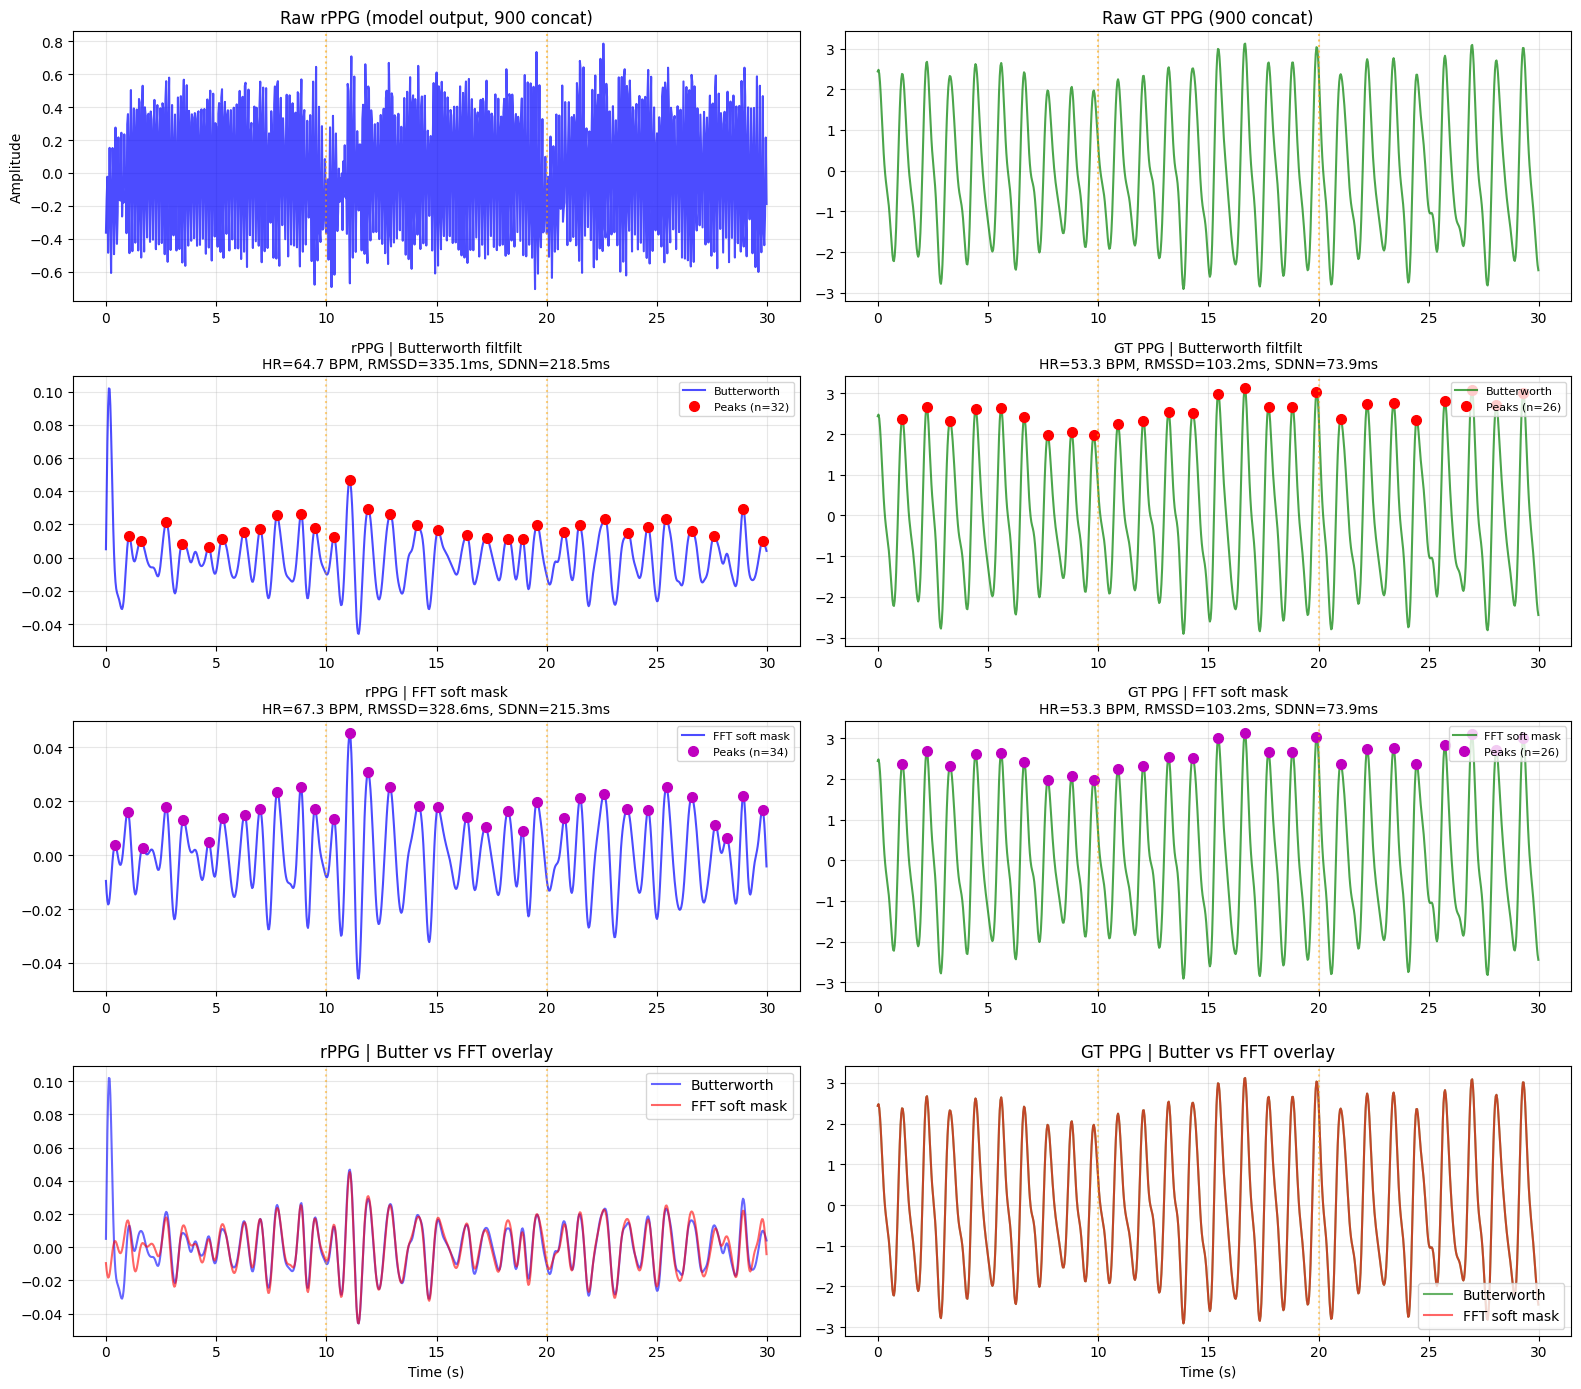

In [22]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
import neurokit2 as nk
from scipy.signal import butter, filtfilt, find_peaks
from astropy.timeseries import LombScargle


# ===== 설정 및 모델 로드 =====
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pth_path = '/home/son/orientation-uv-rppg/data/parameter_save/300franewithoutregis/klloss+ncorshift/0.0001_epoch:96_MAE: 12.58.pth'
data_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_without_registration_cropped_len300'
pic_save_dir = '/home/son/orientation-uv-rppg/data/pics'

model = PhysNet_padding_Encoder_Decoder_MAX().to(device)
model.load_state_dict(torch.load(pth_path, map_location=device))
model.eval()
print("모델 로드 완료")


# ===== 데이터 로드 및 추론 (300×3 → concat 900) =====
all_files = [os.path.join(data_dir, u) for u in sorted(os.listdir(data_dir)) if u.endswith('.h5')]
valid_files = all_files[12:13]
print(valid_files)
valid_dataset = rPPGDataset(valid_files)

GROUP = 3
group_idx = 5   # 몇 번째 900 그룹을 볼지 (= 원래 윈도우 인덱스 15,16,17 묶음)

s = group_idx * GROUP
rppg_parts, gt_parts = [], []
for i in range(s, s + GROUP):
    input_vid, gt_ppg, _ = valid_dataset[i]
    input_vid = input_vid.unsqueeze(0).to(device)   # (1,1,300,64,64)
    with torch.no_grad():
        rppg = model(input_vid)
    rppg_parts.append(rppg.cpu().numpy().flatten().astype(np.float64))   # (300,)
    gt_np = gt_ppg.numpy() if hasattr(gt_ppg, 'numpy') else np.asarray(gt_ppg)
    gt_parts.append(gt_np.astype(np.float64))                            # (300,)

rppg_np   = np.concatenate(rppg_parts)   # (900,)
gt_ppg_np = np.concatenate(gt_parts)     # (900,)
print(f"rPPG: {rppg_np.shape}, GT: {gt_ppg_np.shape}")


# ─────────────────────────────────────────────────────────────
# 1. 두 가지 bandpass
# ─────────────────────────────────────────────────────────────
def butter_bandpass_filter(data, lowcut=0.66, highcut=2.5, fs=30, order=4):
    nyq = 0.5 * fs
    b, a = butter(order, [lowcut/nyq, highcut/nyq], btype='band')
    return filtfilt(b, a, data)


def bandpass_fft_soft(signal, fs=30, low_hz=0.66, high_hz=2.5, steepness=50.0):
    is_numpy = isinstance(signal, np.ndarray)
    if is_numpy:
        signal = torch.tensor(signal, dtype=torch.float32)
    N = signal.shape[-1]
    freqs = torch.fft.rfftfreq(N, d=1.0/fs).to(signal.device)
    fft_signal = torch.fft.rfft(signal)
    mask = torch.sigmoid(steepness * (freqs - low_hz)) * \
           torch.sigmoid(steepness * (high_hz - freqs))
    filtered = torch.fft.irfft(fft_signal * mask, n=N)
    return filtered.cpu().numpy() if is_numpy else filtered


# ─────────────────────────────────────────────────────────────
# 2. HRV 계산 — Contrast-Phys+ 방식 (Lomb-Scargle)
# ─────────────────────────────────────────────────────────────
def compute_hrv_from_rppg(sig, fs=30):
    """Returns hrv_dict, peaks. None on failure. Contrast-Phys+ 호환."""
    try:
        clean = nk.ppg_clean(sig.copy(), sampling_rate=fs, method='elgendi')
        peaks = nk.ppg_findpeaks(clean, sampling_rate=fs)["PPG_Peaks"]
        if len(peaks) < 5:
            return None, peaks

        ibi = (peaks[1:] - peaks[:-1]) / fs   # 초
        ibi_ms = ibi * 1000
        d = np.diff(ibi_ms)

        # time-domain
        mean_hr = 60000.0 / np.mean(ibi_ms)
        sdnn    = np.std(ibi_ms, ddof=1)
        rmssd   = np.sqrt(np.mean(d**2))
        pnn50   = np.mean(np.abs(d) > 50) * 100

        # freq-domain (Lomb-Scargle)
        def find_highest_peak(spec):
            pl = find_peaks(spec)[0]
            return np.argmax(spec) if len(pl) == 0 else pl[np.argmax(spec[pl])]

        lf_power = hf_power = lf_hf = np.nan
        if len(ibi) >= 4:
            freq, power = LombScargle(np.cumsum(ibi), ibi).autopower(
                minimum_frequency=0.01, maximum_frequency=0.51)
            idx_lf = np.where((freq > 0.04) & (freq < 0.15))[0]
            idx_hf = np.where((freq > 0.15) & (freq < 0.40))[0]
            if len(idx_lf) > 0 and len(idx_hf) > 0:
                lf_power = np.sum(power[idx_lf])
                hf_power = np.sum(power[idx_hf])
                if hf_power > 0:
                    lf_hf = lf_power / hf_power

        result = {
            'mean_hr_bpm': mean_hr,
            'rmssd_ms':    rmssd,
            'sdnn_ms':     sdnn,
            'pnn50_pct':   pnn50,
            'lf_power':    lf_power,
            'hf_power':    hf_power,
            'lf_hf_ratio': lf_hf,
            'num_peaks':   len(peaks),
        }
        return result, peaks
    except Exception as e:
        print(f"⚠️ HRV failed: {e}")
        return None, np.array([])


# ─────────────────────────────────────────────────────────────
# 3. 시각화 — 4-panel 비교 (원본과 동일 레이아웃)
# ─────────────────────────────────────────────────────────────
def visualize_filter_comparison(
    rppg_raw, gt_raw,
    rppg_butter, rppg_fft,
    gt_butter, gt_fft,
    rppg_butter_peaks, rppg_fft_peaks,
    gt_butter_peaks, gt_fft_peaks,
    rppg_butter_hrv, rppg_fft_hrv,
    gt_butter_hrv, gt_fft_hrv,
    fs=30, save_path=None
):
    fig, axes = plt.subplots(4, 2, figsize=(16, 14))
    t = np.arange(len(rppg_raw)) / fs

    # 윈도우 경계 표시선 (300, 600 프레임 = 10s, 20s)
    boundaries = [300/fs, 600/fs]

    # Row 0: Raw
    axes[0, 0].plot(t, rppg_raw, 'b-', alpha=0.7)
    axes[0, 0].set_title('Raw rPPG (model output, 900 concat)')
    axes[0, 0].set_ylabel('Amplitude'); axes[0, 0].grid(True, alpha=0.3)
    axes[0, 1].plot(t, gt_raw, 'g-', alpha=0.7)
    axes[0, 1].set_title('Raw GT PPG (900 concat)')
    axes[0, 1].grid(True, alpha=0.3)
    for ax in [axes[0,0], axes[0,1]]:
        for bx in boundaries:
            ax.axvline(bx, color='orange', ls=':', alpha=0.6)

    # Row 1: Butterworth + peaks
    axes[1, 0].plot(t, rppg_butter, 'b-', alpha=0.7, label='Butterworth')
    if len(rppg_butter_peaks) > 0:
        axes[1, 0].plot(rppg_butter_peaks/fs, rppg_butter[rppg_butter_peaks],
                        'ro', markersize=7, label=f'Peaks (n={len(rppg_butter_peaks)})')
    title = 'rPPG | Butterworth filtfilt'
    if rppg_butter_hrv:
        title += f'\nHR={rppg_butter_hrv["mean_hr_bpm"]:.1f} BPM, RMSSD={rppg_butter_hrv["rmssd_ms"]:.1f}ms, SDNN={rppg_butter_hrv["sdnn_ms"]:.1f}ms'
    axes[1, 0].set_title(title, fontsize=10)
    axes[1, 0].legend(loc='upper right', fontsize=8); axes[1, 0].grid(True, alpha=0.3)

    axes[1, 1].plot(t, gt_butter, 'g-', alpha=0.7, label='Butterworth')
    if len(gt_butter_peaks) > 0:
        axes[1, 1].plot(gt_butter_peaks/fs, gt_butter[gt_butter_peaks],
                        'ro', markersize=7, label=f'Peaks (n={len(gt_butter_peaks)})')
    title = 'GT PPG | Butterworth filtfilt'
    if gt_butter_hrv:
        title += f'\nHR={gt_butter_hrv["mean_hr_bpm"]:.1f} BPM, RMSSD={gt_butter_hrv["rmssd_ms"]:.1f}ms, SDNN={gt_butter_hrv["sdnn_ms"]:.1f}ms'
    axes[1, 1].set_title(title, fontsize=10)
    axes[1, 1].legend(loc='upper right', fontsize=8); axes[1, 1].grid(True, alpha=0.3)

    # Row 2: FFT soft mask + peaks
    axes[2, 0].plot(t, rppg_fft, 'b-', alpha=0.7, label='FFT soft mask')
    if len(rppg_fft_peaks) > 0:
        axes[2, 0].plot(rppg_fft_peaks/fs, rppg_fft[rppg_fft_peaks],
                        'mo', markersize=7, label=f'Peaks (n={len(rppg_fft_peaks)})')
    title = 'rPPG | FFT soft mask'
    if rppg_fft_hrv:
        title += f'\nHR={rppg_fft_hrv["mean_hr_bpm"]:.1f} BPM, RMSSD={rppg_fft_hrv["rmssd_ms"]:.1f}ms, SDNN={rppg_fft_hrv["sdnn_ms"]:.1f}ms'
    axes[2, 0].set_title(title, fontsize=10)
    axes[2, 0].legend(loc='upper right', fontsize=8); axes[2, 0].grid(True, alpha=0.3)

    axes[2, 1].plot(t, gt_fft, 'g-', alpha=0.7, label='FFT soft mask')
    if len(gt_fft_peaks) > 0:
        axes[2, 1].plot(gt_fft_peaks/fs, gt_fft[gt_fft_peaks],
                        'mo', markersize=7, label=f'Peaks (n={len(gt_fft_peaks)})')
    title = 'GT PPG | FFT soft mask'
    if gt_fft_hrv:
        title += f'\nHR={gt_fft_hrv["mean_hr_bpm"]:.1f} BPM, RMSSD={gt_fft_hrv["rmssd_ms"]:.1f}ms, SDNN={gt_fft_hrv["sdnn_ms"]:.1f}ms'
    axes[2, 1].set_title(title, fontsize=10)
    axes[2, 1].legend(loc='upper right', fontsize=8); axes[2, 1].grid(True, alpha=0.3)

    # Row 3: overlay
    axes[3, 0].plot(t, rppg_butter, 'b-', alpha=0.6, label='Butterworth')
    axes[3, 0].plot(t, rppg_fft, 'r-', alpha=0.6, label='FFT soft mask')
    axes[3, 0].set_title('rPPG | Butter vs FFT overlay')
    axes[3, 0].set_xlabel('Time (s)'); axes[3, 0].legend(); axes[3, 0].grid(True, alpha=0.3)

    axes[3, 1].plot(t, gt_butter, 'g-', alpha=0.6, label='Butterworth')
    axes[3, 1].plot(t, gt_fft, 'r-', alpha=0.6, label='FFT soft mask')
    axes[3, 1].set_title('GT PPG | Butter vs FFT overlay')
    axes[3, 1].set_xlabel('Time (s)'); axes[3, 1].legend(); axes[3, 1].grid(True, alpha=0.3)

    for bx in boundaries:
        for r in range(1, 4):
            axes[r, 0].axvline(bx, color='orange', ls=':', alpha=0.5)
            axes[r, 1].axvline(bx, color='orange', ls=':', alpha=0.5)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120, bbox_inches='tight')
        print(f"\n💾 Saved: {save_path}")
    plt.show()


# ─────────────────────────────────────────────────────────────
# 4. 필터 적용 — GT는 추가 bandpass 안 함 (이미 필터+znorm)
# ─────────────────────────────────────────────────────────────
rppg_butter = butter_bandpass_filter(rppg_np, fs=30)
rppg_fft    = bandpass_fft_soft(rppg_np, fs=30)
gt_butter   = gt_ppg_np.copy()   # GT: 추가 필터 X
gt_fft      = gt_ppg_np.copy()   # GT: 추가 필터 X

print("="*60)
print("Computing HRV for 4 conditions...")
print("(GT는 이미 bandpass+znorm 적용됨 → 추가 필터 없이 동일 신호 사용)")
print("="*60)

rppg_butter_hrv, rppg_butter_peaks = compute_hrv_from_rppg(rppg_butter)
rppg_fft_hrv,    rppg_fft_peaks    = compute_hrv_from_rppg(rppg_fft)
gt_butter_hrv,   gt_butter_peaks   = compute_hrv_from_rppg(gt_butter)
gt_fft_hrv,      gt_fft_peaks       = compute_hrv_from_rppg(gt_fft)


# ─────────────────────────────────────────────────────────────
# 5. 결과 표 (원본과 동일)
# ─────────────────────────────────────────────────────────────
def print_hrv_table(rppg_b, rppg_f, gt_b, gt_f):
    print("\n" + "="*80)
    print(f"{'Feature':<15} {'GT':<12} {'GT(=)':<12} {'rPPG(Butter)':<14} {'rPPG(FFT)':<12}")
    print("-"*80)
    features = [('HR (BPM)','mean_hr_bpm'), ('RMSSD (ms)','rmssd_ms'),
                ('SDNN (ms)','sdnn_ms'), ('pNN50 (%)','pnn50_pct'),
                ('LF','lf_power'), ('HF','hf_power'),
                ('LF/HF','lf_hf_ratio'), ('# peaks','num_peaks')]
    for label, key in features:
        g_b = f"{gt_b[key]:.2f}" if gt_b else "N/A"
        g_f = f"{gt_f[key]:.2f}" if gt_f else "N/A"
        r_b = f"{rppg_b[key]:.2f}" if rppg_b else "N/A"
        r_f = f"{rppg_f[key]:.2f}" if rppg_f else "N/A"
        print(f"{label:<15} {g_b:<12} {g_f:<12} {r_b:<14} {r_f:<12}")
    print("-"*80)
    print("MAE rPPG vs GT")
    if rppg_b and gt_b:
        print(f"  [Butter→GT] HR={abs(rppg_b['mean_hr_bpm']-gt_b['mean_hr_bpm']):.2f}, "
              f"RMSSD={abs(rppg_b['rmssd_ms']-gt_b['rmssd_ms']):.2f}, "
              f"SDNN={abs(rppg_b['sdnn_ms']-gt_b['sdnn_ms']):.2f}")
    if rppg_f and gt_f:
        print(f"  [FFT→GT]    HR={abs(rppg_f['mean_hr_bpm']-gt_f['mean_hr_bpm']):.2f}, "
              f"RMSSD={abs(rppg_f['rmssd_ms']-gt_f['rmssd_ms']):.2f}, "
              f"SDNN={abs(rppg_f['sdnn_ms']-gt_f['sdnn_ms']):.2f}")
    print("="*80)

print_hrv_table(rppg_butter_hrv, rppg_fft_hrv, gt_butter_hrv, gt_fft_hrv)


# ─────────────────────────────────────────────────────────────
# 6. 시각화
# ─────────────────────────────────────────────────────────────
visualize_filter_comparison(
    rppg_raw=rppg_np, gt_raw=gt_ppg_np,
    rppg_butter=rppg_butter, rppg_fft=rppg_fft,
    gt_butter=gt_butter, gt_fft=gt_fft,
    rppg_butter_peaks=rppg_butter_peaks, rppg_fft_peaks=rppg_fft_peaks,
    gt_butter_peaks=gt_butter_peaks, gt_fft_peaks=gt_fft_peaks,
    rppg_butter_hrv=rppg_butter_hrv, rppg_fft_hrv=rppg_fft_hrv,
    gt_butter_hrv=gt_butter_hrv, gt_fft_hrv=gt_fft_hrv,
    fs=30,
    save_path=os.path.join(pic_save_dir, 'hrv_filter_comparison_900.png'),
)

In [19]:
#physnet hrv

import os
import numpy as np
import torch
from tqdm import tqdm
from scipy.signal import find_peaks, butter, filtfilt
from astropy.timeseries import LombScargle
from scipy.stats import pearsonr
import neurokit2 as nk


# ============================================================
# 1. 설정 + 모델 로드
# ============================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pth_path = '/home/son/orientation-uv-rppg/data/parameter_save/300franewithregis_13out_and_znorm/bandpassbeforelosscompute_negcorloss/physent_data_wo_ol_lr:0.0006000000000000001_epoch:48_MAE: 12.71.pth'
data_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_70_withoutoutlier'

model = PhysNet_padding_Encoder_Decoder_MAX().to(device)
model.load_state_dict(torch.load(pth_path, map_location=device))
model.eval()
print("모델 로드 완료")

all_files = sorted([os.path.join(data_dir, u)
                    for u in os.listdir(data_dir) if u.endswith('.h5')])
valid_files = all_files[12:]
valid_dataset = rPPGDataset(valid_files)
print(f"파일 {len(valid_files)}개, 총 윈도우 {len(valid_dataset)}개")


# ============================================================
# 2. HRV 추출 함수 (Contrast-Phys+ 호환 + time-domain 추가)
# ============================================================
def butter_bandpass_filter(data, lowcut=0.66, highcut=2.5, fs=30, order=4):
    nyq = 0.5 * fs
    b, a = butter(order, [lowcut/nyq, highcut/nyq], btype='band')
    return filtfilt(b, a, data)


def get_ibi(sig, fps=30):
    """Contrast-Phys+ 원본. IBI 단위는 초."""
    try:
        ppg_clean = nk.ppg_clean(sig.copy(), sampling_rate=fps, method='elgendi')
        info = nk.ppg_findpeaks(ppg_clean, sampling_rate=fps)
        peak_loc = info["PPG_Peaks"]
        if len(peak_loc) < 5:
            return None, peak_loc
        ibi = (peak_loc[1:] - peak_loc[:-1]) / fps   # 초
        return ibi, peak_loc
    except Exception as e:
        return None, np.array([])


def freq_features(ibi):
    """Lomb-Scargle 기반 LF/HF. Contrast-Phys+ 원본 + 안전장치."""
    if len(ibi) < 4:
        return None
    
    def find_highest_peak(sig):
        peak_loc = find_peaks(sig)[0]
        if len(peak_loc) == 0:
            return np.argmax(sig)
        return peak_loc[np.argmax(sig[peak_loc])]
    
    freq, power = LombScargle(np.cumsum(ibi), ibi).autopower(
        minimum_frequency=0.01, maximum_frequency=0.51
    )
    idx_lf = np.where((freq > 0.04) & (freq < 0.15))[0]
    idx_hf = np.where((freq > 0.15) & (freq < 0.40))[0]
    if len(idx_lf) == 0 or len(idx_hf) == 0:
        return None
    
    power_lf = np.sum(power[idx_lf])
    power_hf = np.sum(power[idx_hf])
    if power_hf == 0:
        return None
    
    return {
        'lf_f':  freq[idx_lf][find_highest_peak(power[idx_lf])],
        'hf_f':  freq[idx_hf][find_highest_peak(power[idx_hf])],
        'lfnu':  power_lf / (power_lf + power_hf),
        'hfnu':  power_hf / (power_lf + power_hf),
        'lf_hf': power_lf / power_hf,
    }


def time_features(ibi):
    """Time-domain HRV. IBI 입력은 초, 출력은 ms."""
    if len(ibi) < 3:
        return None
    ibi_ms = ibi * 1000
    diff = np.diff(ibi_ms)
    return {
        'mean_hr': 60000.0 / np.mean(ibi_ms),
        'sdnn':    np.std(ibi_ms, ddof=1),
        'rmssd':   np.sqrt(np.mean(diff**2)),
        'pnn50':   np.mean(np.abs(diff) > 50) * 100,
    }


def compute_all_hrv(sig, fps=30, use_bandpass=True):
    """한 윈도우에 대한 통합 HRV (time + freq)."""
    if use_bandpass:
        sig = butter_bandpass_filter(sig, fs=fps)
    
    ibi, peaks = get_ibi(sig, fps)
    if ibi is None:
        return None
    
    result = {'num_peaks': len(peaks)}
    tf = time_features(ibi)
    ff = freq_features(ibi)
    if tf is None or ff is None:
        return None
    result.update(tf)
    result.update(ff)
    return result


# ============================================================
# 3. 전체 윈도우 평가 루프
# ============================================================
results = []
USE_BANDPASS = True  # Contrast-Phys+ 그대로 = False. raw 품질 낮으면 True 시도

for i in tqdm(range(len(valid_dataset)), desc="HRV"):
    input_vid, gt_ppg, _ = valid_dataset[i]
    input_vid = input_vid.unsqueeze(0).to(device)
    
    with torch.no_grad():
        rppg = model(input_vid)
    
    rppg_np   = rppg.cpu().numpy().flatten().astype(np.float64)
    gt_ppg_np = (gt_ppg.numpy() if hasattr(gt_ppg, 'numpy')
                 else np.asarray(gt_ppg)).astype(np.float64)
    
    r_pred = compute_all_hrv(rppg_np,   fps=30, use_bandpass=USE_BANDPASS)
    r_gt   = compute_all_hrv(gt_ppg_np, fps=30, use_bandpass=USE_BANDPASS)
    
    results.append({'pred': r_pred, 'gt': r_gt})


# ============================================================
# 4. 페어드 메트릭 (Contrast-Phys+ Table 2 호환: STD / RMSE / R + MAE)
# ============================================================
def paired_metrics(metric_key):
    pairs = [(r['pred'][metric_key], r['gt'][metric_key])
             for r in results
             if r['pred'] is not None and r['gt'] is not None
             and metric_key in r['pred'] and metric_key in r['gt']
             and np.isfinite(r['pred'][metric_key])
             and np.isfinite(r['gt'][metric_key])]
    if len(pairs) < 2:
        return None
    pred = np.array([p for p, _ in pairs])
    gt   = np.array([g for _, g in pairs])
    err  = pred - gt
    return {
        'pred_mean': pred.mean(),
        'gt_mean':   gt.mean(),
        'MAE':       np.mean(np.abs(err)),
        'STD':       np.std(err, ddof=1),
        'RMSE':      np.sqrt(np.mean(err**2)),
        'R':         pearsonr(pred, gt)[0] if np.std(pred) > 0 and np.std(gt) > 0 else np.nan,
        'n':         len(pairs),
    }


# ============================================================
# 5. 결과 출력 — 두 가지 표
# ============================================================

# ───── 표 1: Contrast-Phys+ Table 2 직접 비교용 ─────
print("\n" + "="*78)
print("[표 1] Contrast-Phys+ Table 2 직접 비교 (UBFC-rPPG → CNA 본인 결과)")
print("="*78)
print(f"{'Metric':<14}{'STD':<10}{'RMSE':<10}{'MAE':<10}{'R':<10}{'n':<6}")
print("-"*78)
for label, key in [('LF (n.u.)',  'lfnu'),
                   ('HF (n.u.)',  'hfnu'),
                   ('LF/HF',      'lf_hf'),
                   ('RF (Hz)',    'hf_f')]:
    m = paired_metrics(key)
    if m:
        print(f"{label:<14}{m['STD']:<10.3f}{m['RMSE']:<10.3f}"
              f"{m['MAE']:<10.3f}{m['R']:<10.3f}{m['n']:<6}")
    else:
        print(f"{label:<14}{'N/A':<10}")





# ───── 표 2: Sleep stage 분류용 time-domain HRV ─────
print("\n" + "="*78)
print("[표 2] Time-domain HRV (Sleep stage 분류용)")
print("="*78)
print(f"{'Metric':<14}{'pred_mean':<12}{'gt_mean':<12}"
      f"{'MAE':<10}{'RMSE':<10}{'R':<10}{'n':<6}")
print("-"*78)
for label, key in [('HR (BPM)',   'mean_hr'),
                   ('RMSSD (ms)', 'rmssd'),
                   ('SDNN (ms)',  'sdnn'),
                   ('pNN50 (%)',  'pnn50')]:
    m = paired_metrics(key)
    if m:
        print(f"{label:<14}{m['pred_mean']:<12.2f}{m['gt_mean']:<12.2f}"
              f"{m['MAE']:<10.2f}{m['RMSE']:<10.2f}{m['R']:<10.3f}{m['n']:<6}")
    else:
        print(f"{label:<14}{'N/A':<10}")

# 참고: Sleep stage 분류 가능 임계
print("-"*78)
print("[참고] Sleep stage 분류 가능선 (이전 대화 정리):")
print(f"  HR MAE ≤ 3 BPM,  RMSSD MAE ≤ 10 ms,  SDNN MAE ≤ 10~15 ms")


# ───── 윈도우 통계 ─────
n_total = len(results)
n_valid = sum(1 for r in results if r['pred'] is not None and r['gt'] is not None)
n_pred_fail = sum(1 for r in results if r['pred'] is None)
n_gt_fail   = sum(1 for r in results if r['gt']   is None)

print("\n" + "="*78)
print(f"전체 윈도우: {n_total}")
print(f"  유효 페어:    {n_valid} ({100*n_valid/n_total:.1f}%)")
print(f"  rPPG 실패:    {n_pred_fail}")
print(f"  GT 실패:      {n_gt_fail}")
print("="*78)

모델 로드 완료
파일 4개, 총 윈도우 340개


HRV: 100%|██████████| 340/340 [04:17<00:00,  1.32it/s]


[표 1] Contrast-Phys+ Table 2 직접 비교 (UBFC-rPPG → CNA 본인 결과)
Metric        STD       RMSE      MAE       R         n     
------------------------------------------------------------------------------
LF (n.u.)     0.219     0.222     0.172     -0.011    236   
HF (n.u.)     0.219     0.222     0.172     -0.011    236   
LF/HF         1.135     1.191     0.622     -0.055    236   
RF (Hz)       0.082     0.083     0.068     -0.077    236   

[표 2] Time-domain HRV (Sleep stage 분류용)
Metric        pred_mean   gt_mean     MAE       RMSE      R         n     
------------------------------------------------------------------------------
HR (BPM)      21.52       60.41       39.60     42.88     0.108     236   
RMSSD (ms)    8061.13     72.53       7988.60   10490.05  -0.102    236   
SDNN (ms)     5404.37     65.46       5338.91   6801.73   -0.205    236   
pNN50 (%)     95.47       42.74       52.90     56.70     -0.055    236   
-------------------------------------------------------------